# E-Commerce Dataset Analysis

## Objective
Analyze an e-commerce dataset to understand customer orders, revenue trends, product performance, and geographical sales patterns.

### Key Objectives
- Analyze customer orders and purchasing behavior.
- Analyze sales revenue and monthly revenue trends.
- Identify best-selling products.
- Identify high-revenue products and countries.
- Visualize important findings using bar and pie charts.
- Generate actionable business insights and recommendations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
df = pd.read_csv("../data/OnlineRetail.csv", encoding="ISO-8859-1")

print("Dataset loaded successfully.")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully.
Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [3]:
print("Dataset Information")
print("=" * 50)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Dataset Information
Rows: 541909
Columns: 8

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data Types:
InvoiceNo          str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
UnitPrice      float64
CustomerID     float64
Country            str
dtype: object


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


In [5]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
InvoiceNo,541909,25900,573585,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,218.081158,-80995.0,1.0,3.0,10.0,80995.0
InvoiceDate,541909,23260,10/31/2011 14:41,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,96.759853,-11062.06,1.25,2.08,4.13,38970.0
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,1713.600303,12346.0,13953.0,15152.0,16791.0,18287.0
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(df)) * 100
})

missing_summary.sort_values(
    by="Missing Values",
    ascending=False
)

,Missing Values,Missing Percentage
CustomerID,135080,24.926694
Description,1454,0.268311
StockCode,0,0.000000
InvoiceNo,0,0.000000
Quantity,0,0.000000
InvoiceDate,0,0.000000
UnitPrice,0,0.000000
Country,0,0.000000


In [7]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 5268


In [8]:
print("Negative Quantity:", (df["Quantity"] < 0).sum())
print("Zero Quantity:", (df["Quantity"] == 0).sum())
print("Negative Unit Price:", (df["UnitPrice"] < 0).sum())
print("Zero Unit Price:", (df["UnitPrice"] == 0).sum())

Negative Quantity: 10624
Zero Quantity: 0
Negative Unit Price: 2
Zero Unit Price: 2515


In [9]:
cancelled_orders = df["InvoiceNo"].astype(str).str.startswith("C").sum()

print("Cancelled invoices:", cancelled_orders)

Cancelled invoices: 9288


In [11]:
df_clean = df.copy()

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

# Remove rows with missing product descriptions
df_clean = df_clean.dropna(subset=["Description"])

# Remove invalid quantities
df_clean = df_clean[df_clean["Quantity"] > 0]

# Remove invalid prices
df_clean = df_clean[df_clean["UnitPrice"] > 0]

# Remove cancelled invoices
df_clean = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
]

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

Original dataset shape: (541909, 8)
Cleaned dataset shape: (524878, 8)


In [12]:
print("Missing Customer IDs:", df_clean["CustomerID"].isnull().sum())
print(
    "Percentage missing:",
    round(df_clean["CustomerID"].isnull().mean() * 100, 2),
    "%"
)

Missing Customer IDs: 132186
Percentage missing: 25.18 %


In [13]:
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["UnitPrice"]

df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"],
    errors="coerce"
)

df_clean["Year"] = df_clean["InvoiceDate"].dt.year
df_clean["Month"] = df_clean["InvoiceDate"].dt.month
df_clean["Month_Name"] = df_clean["InvoiceDate"].dt.strftime("%B")

print("Feature engineering completed.")

df_clean.head()

Feature engineering completed.


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Year,Month,Month_Name
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010,12,December
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,December
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010,12,December
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,December
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,December


In [14]:
total_revenue = df_clean["Revenue"].sum()
average_transaction_value = df_clean["Revenue"].mean()
total_quantity = df_clean["Quantity"].sum()
unique_products = df_clean["StockCode"].nunique()
unique_customers = df_clean["CustomerID"].nunique()
unique_orders = df_clean["InvoiceNo"].nunique()

print("E-Commerce Business Summary")
print("=" * 50)
print(f"Total Revenue: ${total_revenue:,.2f}")
print(f"Average Transaction Value: ${average_transaction_value:,.2f}")
print(f"Total Quantity Sold: {total_quantity:,.0f}")
print(f"Unique Products: {unique_products:,}")
print(f"Unique Customers: {unique_customers:,}")
print(f"Unique Orders: {unique_orders:,}")

E-Commerce Business Summary
Total Revenue: $10,642,110.80
Average Transaction Value: $20.28
Total Quantity Sold: 5,572,420
Unique Products: 3,922
Unique Customers: 4,338
Unique Orders: 19,960


In [15]:
customer_orders = (
    df_clean.groupby("CustomerID")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
)

print("Top 10 Customers by Number of Orders")
customer_orders.head(10)

Top 10 Customers by Number of Orders


CustomerID
12748.0    209
14911.0    201
17841.0    124
13089.0     97
14606.0     93
15311.0     91
12971.0     86
14646.0     73
16029.0     63
13408.0     62
Name: InvoiceNo, dtype: int64

In [16]:
customer_revenue = (
    df_clean.groupby("CustomerID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Customers by Revenue")
customer_revenue.head(10)

Top 10 Customers by Revenue


CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80850.84
12346.0     77183.60
Name: Revenue, dtype: float64

In [17]:
product_quantity = (
    df_clean.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Best-Selling Products by Quantity")
product_quantity.head(10)

Top 10 Best-Selling Products by Quantity


Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64

In [18]:
product_revenue = (
    df_clean.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Products by Revenue")
product_revenue.head(10)

Top 10 Products by Revenue


Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: Revenue, dtype: float64

In [19]:
country_revenue = (
    df_clean.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Countries by Revenue")
country_revenue.head(10)

Top 10 Countries by Revenue


Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64

In [20]:
country_orders = (
    df_clean.groupby("Country")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
)

print("Top 10 Countries by Number of Orders")
country_orders.head(10)

Top 10 Countries by Number of Orders


Country
United Kingdom    18019
Germany             457
France              392
EIRE                288
Belgium              98
Netherlands          94
Spain                90
Portugal             58
Australia            57
Switzerland          54
Name: InvoiceNo, dtype: int64

In [21]:
monthly_revenue = (
    df_clean.groupby(
        df_clean["InvoiceDate"].dt.to_period("M")
    )["Revenue"]
    .sum()
)

monthly_revenue.index = monthly_revenue.index.astype(str)

print(monthly_revenue)

InvoiceDate
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637790.330
Name: Revenue, dtype: float64


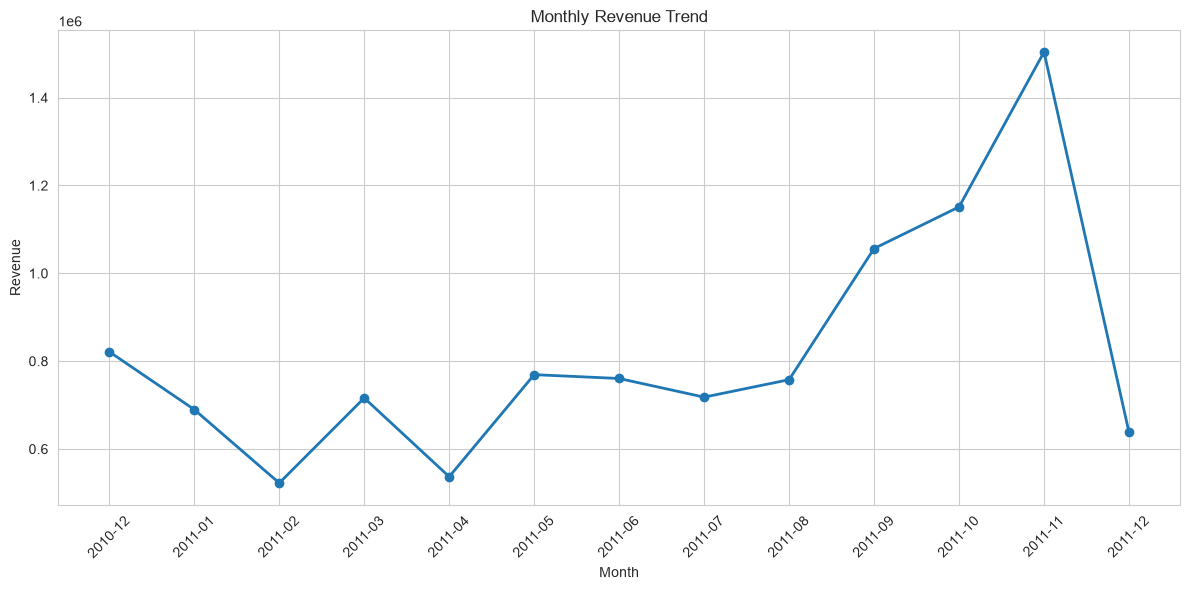

In [22]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_revenue.index,
    monthly_revenue.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "../visuals/monthly_revenue_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

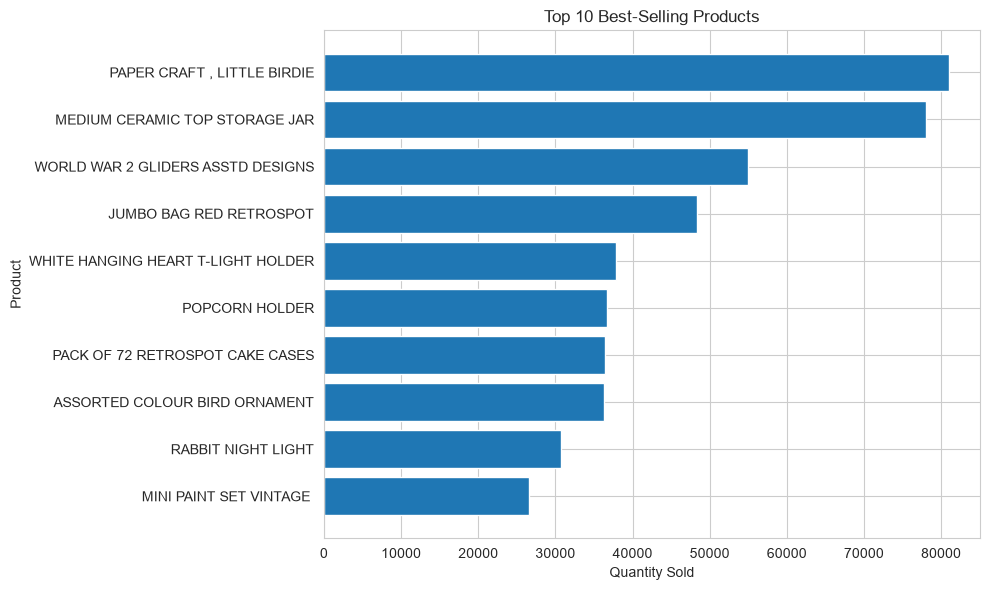

In [23]:
top_products = product_quantity.head(10).sort_values()

plt.figure(figsize=(10, 6))

plt.barh(
    top_products.index,
    top_products.values
)

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")

plt.tight_layout()

plt.savefig(
    "../visuals/top_10_best_selling_products.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

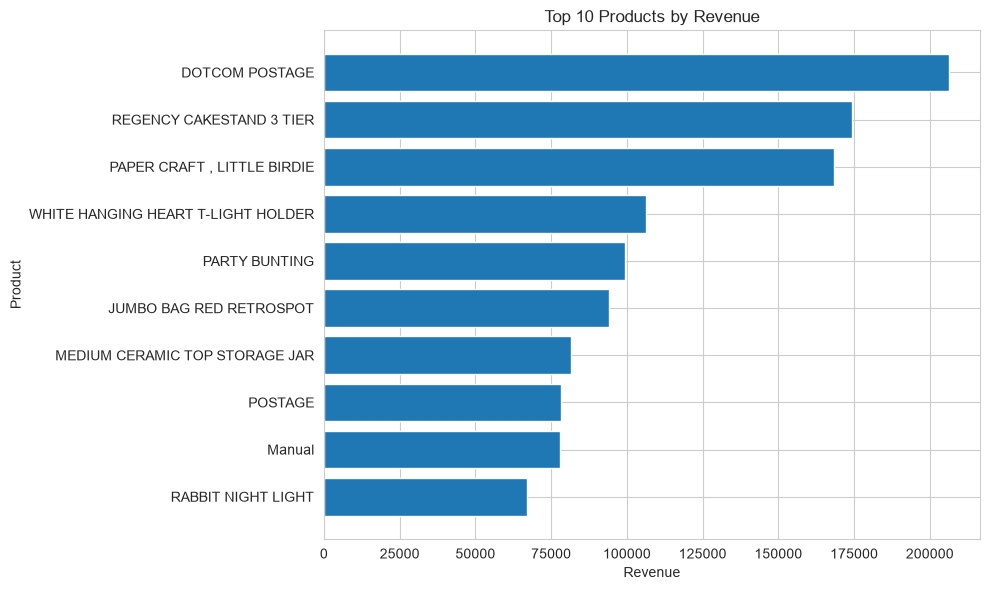

In [24]:
top_revenue_products = product_revenue.head(10).sort_values()

plt.figure(figsize=(10, 6))

plt.barh(
    top_revenue_products.index,
    top_revenue_products.values
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")

plt.tight_layout()

plt.savefig(
    "../visuals/top_10_revenue_products.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

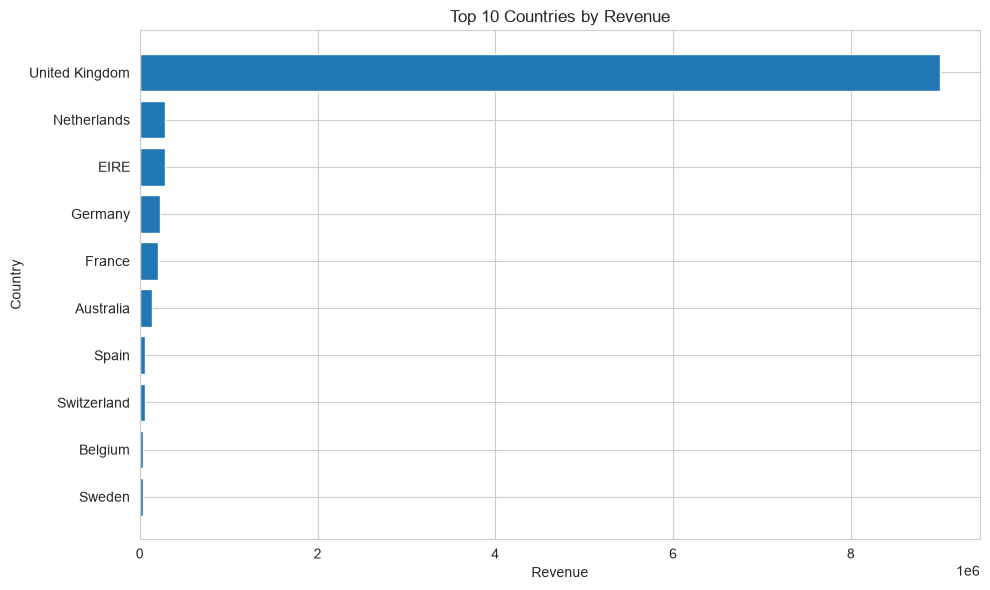

In [25]:
top_countries = country_revenue.head(10).sort_values()

plt.figure(figsize=(10, 6))

plt.barh(
    top_countries.index,
    top_countries.values
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Country")

plt.tight_layout()

plt.savefig(
    "../visuals/top_10_countries_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

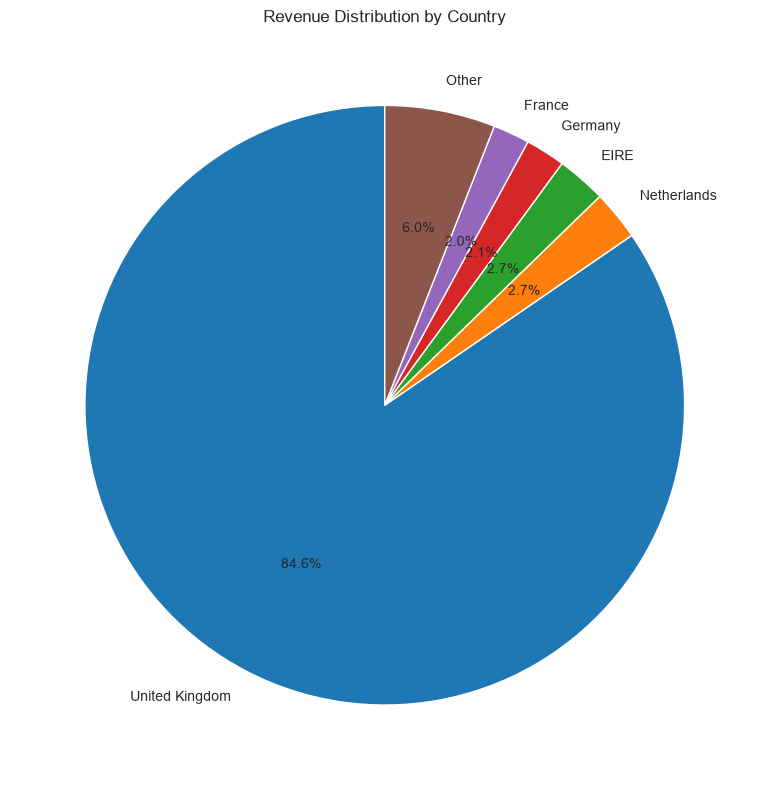

In [26]:
country_pie = country_revenue.head(5).copy()

other_revenue = country_revenue.iloc[5:].sum()

country_pie["Other"] = other_revenue

plt.figure(figsize=(8, 8))

plt.pie(
    country_pie.values,
    labels=country_pie.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Revenue Distribution by Country")

plt.tight_layout()

plt.savefig(
    "../visuals/revenue_distribution_by_country.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

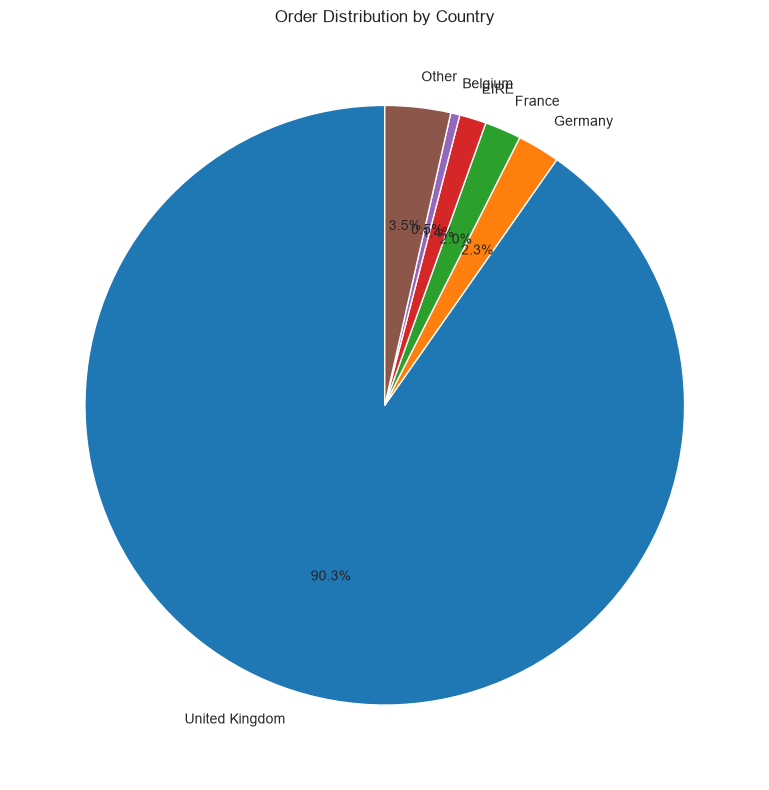

In [27]:
order_distribution = country_orders.head(5).copy()

other_orders = country_orders.iloc[5:].sum()

order_distribution["Other"] = other_orders

plt.figure(figsize=(8, 8))

plt.pie(
    order_distribution.values,
    labels=order_distribution.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Order Distribution by Country")

plt.tight_layout()

plt.savefig(
    "../visuals/order_distribution_by_country.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [28]:
yearly_revenue = (
    df_clean.groupby("Year")["Revenue"]
    .sum()
)

print("Yearly Revenue")
print(yearly_revenue)

Yearly Revenue
Year
2010     821452.730
2011    9820658.074
Name: Revenue, dtype: float64


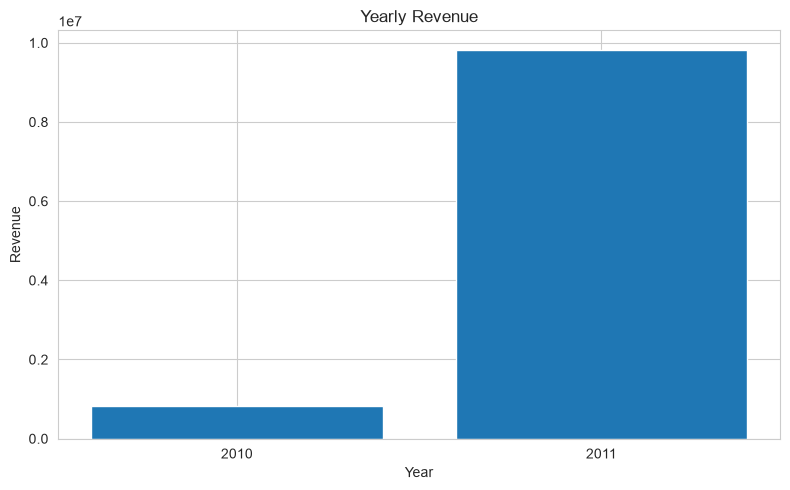

In [29]:
plt.figure(figsize=(8, 5))

plt.bar(
    yearly_revenue.index.astype(str),
    yearly_revenue.values
)

plt.title("Yearly Revenue")
plt.xlabel("Year")
plt.ylabel("Revenue")

plt.tight_layout()

plt.savefig(
    "../visuals/yearly_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

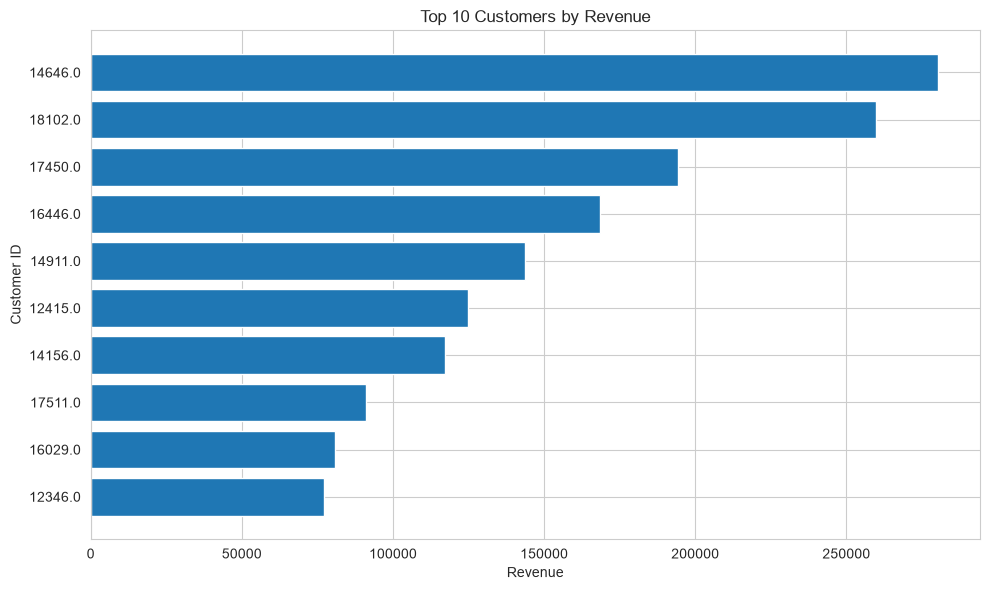

In [30]:
top_customers = customer_revenue.head(10).sort_values()

plt.figure(figsize=(10, 6))

plt.barh(
    top_customers.index.astype(str),
    top_customers.values
)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Customer ID")

plt.tight_layout()

plt.savefig(
    "../visuals/top_10_customers_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Key Business Insights

1. The analysis identifies the products generating the highest sales volume and revenue.
2. Customer-level analysis highlights high-value customers based on total revenue and order frequency.
3. Monthly revenue trends show how sales performance changes over time.
4. Country-level analysis identifies the strongest geographical markets.
5. Revenue concentration across major countries can help prioritize international sales and marketing efforts.
6. Best-selling products can be prioritized for inventory planning and promotional campaigns.
7. High-revenue products should receive particular attention because they contribute significantly to overall business performance.

## Recommendations

- Prioritize inventory planning for the best-selling products.
- Develop targeted promotions for high-revenue products.
- Focus marketing efforts on countries contributing the highest revenue.
- Identify high-value customers and design customer-retention strategies for them.
- Monitor monthly revenue trends to identify periods of strong and weak performance.
- Investigate products with high sales volume but relatively low revenue to evaluate pricing opportunities.
- Use customer order history to develop personalized offers and cross-selling strategies.

## Conclusion

The e-commerce dataset analysis provides insights into customer purchasing behavior, product performance, revenue generation, and geographical sales distribution. The analysis identifies best-selling products, high-revenue products, valuable customers, major markets, and revenue trends over time. These findings can support inventory planning, customer retention, marketing decisions, and revenue optimization.